In [2]:
import pandas as pd
import numpy as np
from cross_validation import cross_validation

In [3]:
#get all answers from all iterations and CVs
all_answers = []

# Originalna datoteka
df0 = pd.read_excel(
    "../batches/original_train_for_aa.xlsx",
    engine="openpyxl"
)

df0["iteration"] = -1
all_answers.append(df0)

# Iteracije 0–19
for i in range(20):
    df = pd.read_excel(
        f"../batches/to_label_iteration_{i}.xlsx",
        engine="openpyxl"
    )

    df["iteration"] = i
    all_answers.append(df)

# CV2
df2 = pd.read_excel(
    "../batches/to_label_iteration_CV2.xlsx",
    engine="openpyxl"
)

df2["iteration"] = 22
all_answers.append(df2)

# CV3
df3 = pd.read_excel(
    "../batches/to_label_iteration_CV3.xlsx",
    engine="openpyxl"
)

df3["iteration"] = 23
all_answers.append(df3)

# Združimo vse podatke
answers = pd.concat(all_answers, ignore_index=True)

# Obdržimo najnovejšo odločitev za vsak kontig
answers = (
    answers
    .sort_values("iteration", kind="stable")
    .drop_duplicates(
        subset=["SAMPLE", "CONTIG NAME"],
        keep="last"
    )
    .reset_index(drop=True)
)

#answers.to_excel("annotator_answers.xlsx", index=False)

#answers.to_csv("annotator_answers.tsv",sep="\t",index=False)


In [4]:
#keep only relevant columns
columns_to_keep = ["SAMPLE", "CONTIG NAME", "Pia","Lana","Denis","iteration"]
answers_without_info = answers[columns_to_keep]


In [6]:
#cross validation for all the conigs
cross_validation(train_file = "annotator_answers.tsv", output_file = "annotator_LOOCV")

1/662
2/662
3/662
4/662
5/662
6/662
7/662
8/662
9/662
10/662
11/662
12/662
13/662
14/662
15/662
16/662
17/662
18/662
19/662
20/662
21/662
22/662
23/662
24/662
25/662
26/662
27/662
28/662
29/662
30/662
31/662
32/662
33/662
34/662
35/662
36/662
37/662
38/662
39/662
40/662
41/662
42/662
43/662
44/662
45/662
46/662
47/662
48/662
49/662
50/662
51/662
52/662
53/662
54/662
55/662
56/662
57/662
58/662
59/662
60/662
61/662
62/662
63/662
64/662
65/662
66/662
67/662
68/662
69/662
70/662
71/662
72/662
73/662
74/662
75/662
76/662
77/662
78/662
79/662
80/662
81/662
82/662
83/662
84/662
85/662
86/662
87/662
88/662
89/662
90/662
91/662
92/662
93/662
94/662
95/662
96/662
97/662
98/662
99/662
100/662
101/662
102/662
103/662
104/662
105/662
106/662
107/662
108/662
109/662
110/662
111/662
112/662
113/662
114/662
115/662
116/662
117/662
118/662
119/662
120/662
121/662
122/662
123/662
124/662
125/662
126/662
127/662
128/662
129/662
130/662
131/662
132/662
133/662
134/662
135/662
136/662
137/662
138/662
139/

,SAMPLE,CONTIG NAME,LENGTH,SPADES_COV,REALM,KINGDOM,PHYLUM,CLASS,ORDER,FAMILY,...,Sequence,id,cov,Change?,TRUE_LABEL,MODEL_PREDICTION,PROB_NO,PROB_YES,CONFIDENCE,CORRECT
0,ERR12670428,NODE_39,8689,11.744777,unclassified Riboviria,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,No,Yes,0.204966,0.795034,0.795034,False
1,ERR12670382,NODE_32,7896,1307.634028,Riboviria,Orthornavirae,Kitrinoviricota,Alsuviricetes,Tymovirales,NaN,...,NaN,NaN,NaN,NaN,Yes,Yes,0.001401,0.998599,0.998599,True
2,ERR12670510,NODE_116,6655,29.141446,Riboviria,Orthornavirae,Pisuviricota,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,No,Yes,0.060017,0.939983,0.939983,False
3,ERR12670452,NODE_139,6373,9.738571,Riboviria,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,No,No,0.547460,0.452540,0.547460,True
4,ERR12670453,NODE_480,5011,14.282301,Riboviria,Orthornavirae,Pisuviricota,Pisoniviricetes,Picornavirales,NaN,...,NaN,NaN,NaN,NaN,No,No,0.984892,0.015108,0.984892,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
657,ERR12670509,NODE_53568,604,1.574388,Riboviria,Orthornavirae,Kitrinoviricota,Alsuviricetes,Tymovirales,Alphaflexiviridae,...,NaN,49.4,97.22,NaN,Yes,No,0.951066,0.048934,0.951066,False
658,ERR12670319,NODE_65061,507,1.670507,Riboviria,Orthornavirae,Pisuviricota,Stelpaviricetes,Stellavirales,Astroviridae,...,NaN,32.6,91.3,NaN,Yes,Yes,0.399486,0.600514,0.600514,True
659,ERR12670346,NODE_70,6995,26.105172,Riboviria,Orthornavirae,Pisuviricota,Pisoniviricetes,Picornavirales,Dicistroviridae,...,NaN,NaN,NaN,NaN,Yes,Yes,0.028775,0.971225,0.971225,True
660,ERR12670453,NODE_92,6939,36.347509,Riboviria,Orthornavirae,Pisuviricota,Duplopiviricetes,Durnavirales,NaN,...,NaN,51.0,68.87,NaN,Yes,Yes,0.013287,0.986713,0.986713,True


In [7]:
#merge the predictions with the answers
loocv = pd.read_csv("annotator_LOOCV")

answers_with_model = answers_without_info.merge(
    loocv[["SAMPLE", "CONTIG NAME", "MODEL_PREDICTION"]],
    on=["SAMPLE", "CONTIG NAME"],
    how="left",
    validate="one_to_one"
)

In [43]:
for col in ["Pia", "Lana", "Denis", "MODEL_PREDICTION"]:
    print("\n", col)
    print(answers_with_model[col].value_counts(dropna=False))


 Pia
Pia
No       458
Yes      149
?         35
no         8
yes        5
Yes?       4
Yes ?      1
 No        1
No?        1
Name: count, dtype: int64

 Lana
Lana
No     444
Yes    214
?        4
Name: count, dtype: int64

 Denis
Denis
no     228
No     210
yes    133
Yes     64
?       26
Np       1
Name: count, dtype: int64

 MODEL_PREDICTION
MODEL_PREDICTION
No     432
Yes    230
Name: count, dtype: int64


In [8]:

cols = ["Pia", "Lana", "Denis", "MODEL_PREDICTION"]

for col in cols:
    answers_with_model[col] = (
        answers_with_model[col]
        .astype("string")
        .str.strip()                  # odstrani presledke na začetku in koncu
        .str.replace("?", "", regex=False)  # odstrani ?
        .str.strip()                  # odstrani preostale presledke
        .str.capitalize()             # yes -> Yes, no -> No
        .replace({"Np": "No", "": "?"})
    )


In [9]:
for col in ["Pia", "Lana", "Denis", "MODEL_PREDICTION"]:
    print("\n", col)
    print(answers_with_model[col].value_counts(dropna=False))


 Pia
Pia
No     468
Yes    159
?       35
Name: count, dtype: Int64

 Lana
Lana
No     444
Yes    214
?        4
Name: count, dtype: Int64

 Denis
Denis
No     439
Yes    197
?       26
Name: count, dtype: Int64

 MODEL_PREDICTION
MODEL_PREDICTION
No     432
Yes    230
Name: count, dtype: Int64


In [10]:
answers_with_model["ID"] = (
    answers_with_model["SAMPLE"].astype(str)
    + "_"
    + answers_with_model["CONTIG NAME"].astype(str)
)

In [11]:
annotators = ["MODEL_PREDICTION", "Pia", "Lana", "Denis"]

# Samo kontigi, kjer imajo vsi veljavno oznako
common_answers = answers_with_model[
    answers_with_model[annotators]
    .isin(["Yes", "No"])
    .all(axis=1)
].copy()

In [12]:
model_yes = set(common_answers.loc[common_answers["MODEL_PREDICTION"] == "Yes", "ID"])
pia_yes   = set(common_answers.loc[common_answers["Pia"] == "Yes", "ID"])
lana_yes  = set(common_answers.loc[common_answers["Lana"] == "Yes", "ID"])
denis_yes = set(common_answers.loc[common_answers["Denis"] == "Yes", "ID"])

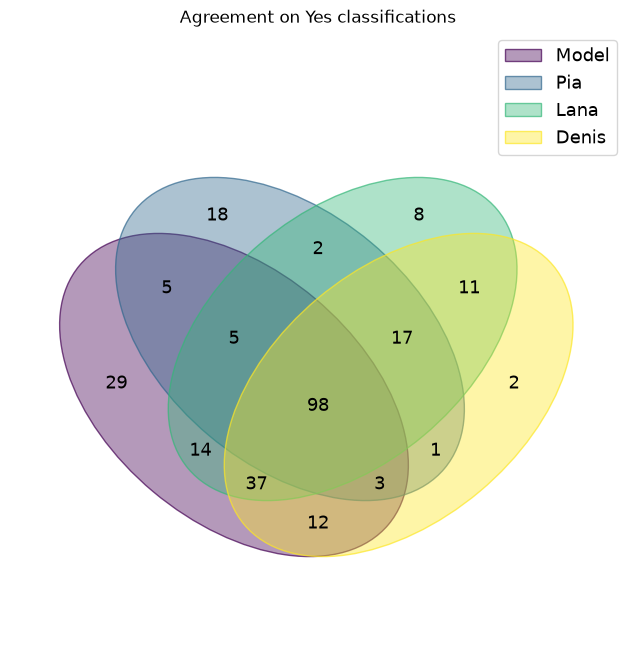

In [13]:
from venn import venn
import matplotlib.pyplot as plt

sets_Yes = {
    "Model": model_yes,
    "Pia": pia_yes,
    "Lana": lana_yes,
    "Denis": denis_yes
}

venn(sets_Yes)

plt.title("Agreement on Yes classifications")
plt.show()

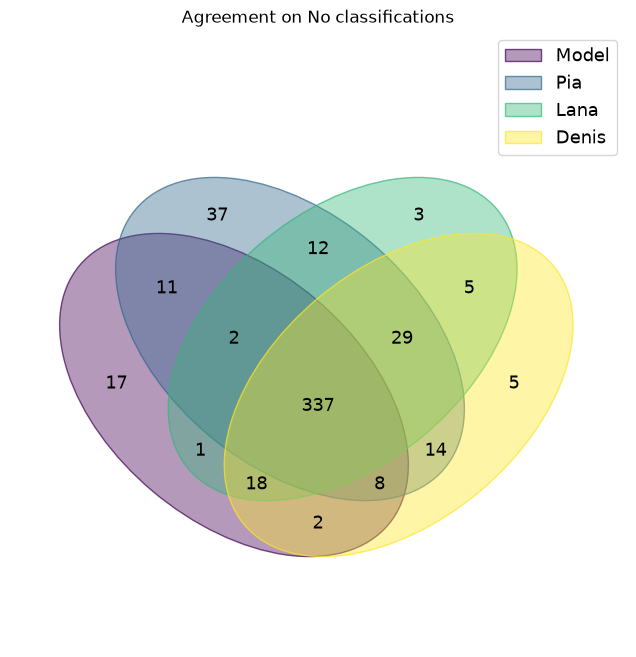

In [14]:
model_no = set(common_answers.loc[common_answers["MODEL_PREDICTION"] == "No", "ID"])
pia_no   = set(common_answers.loc[common_answers["Pia"] == "No", "ID"])
lana_no  = set(common_answers.loc[common_answers["Lana"] == "No", "ID"])
denis_no = set(common_answers.loc[common_answers["Denis"] == "No", "ID"])

sets_No = {
    "Model": model_no,
    "Pia": pia_no,
    "Lana": lana_no,
    "Denis": denis_no
}

venn(sets_No)

plt.title("Agreement on No classifications")
plt.show()

In [15]:
name_mapping = {
    "Pia": "Ocenjevalec 1",
    "Lana": "Ocenjevalec 2",
    "Denis": "Ocenjevalec 3",
    "MODEL_PREDICTION": "Model"
}

sets_Yes_plot = {
    name_mapping.get(name, name): values
    for name, values in sets_Yes.items()
}

sets_No_plot = {
    name_mapping.get(name, name): values
    for name, values in sets_No.items()
}

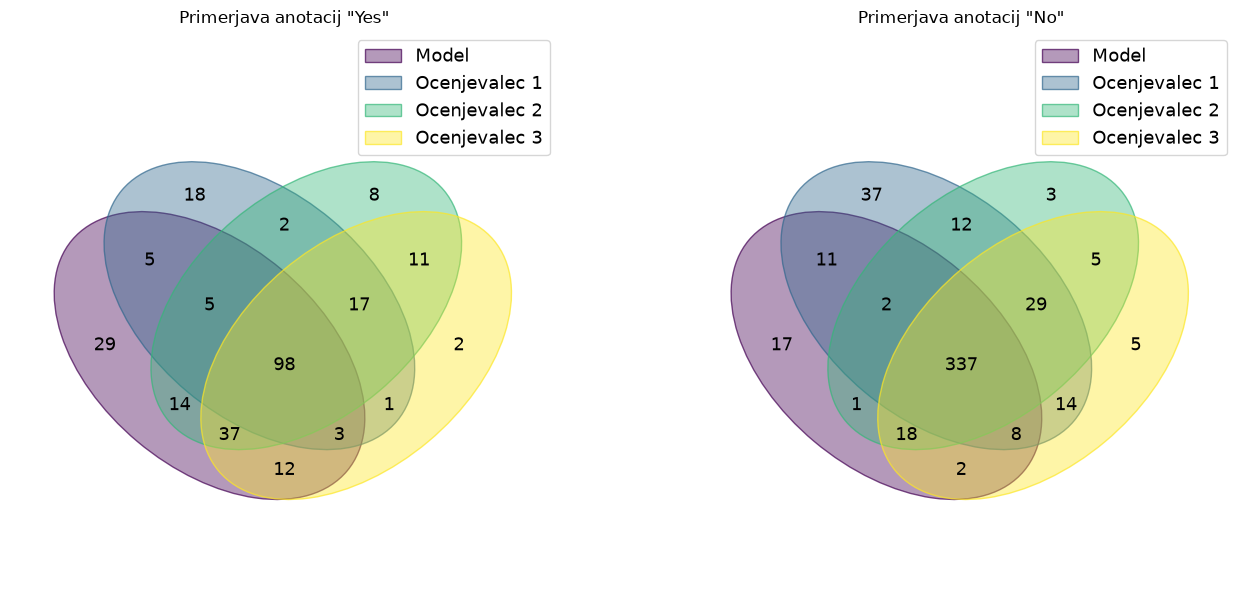

In [16]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

venn(
    sets_Yes_plot,
    ax=axes[0]
)
axes[0].set_title(
    'Primerjava anotacij "Yes"'
)

venn(
    sets_No_plot,
    ax=axes[1]
)
axes[1].set_title(
    'Primerjava anotacij "No"'
)

plt.tight_layout()

plt.savefig(
    "venn_agreement_yes_no.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "venn_agreement_yes_no.pdf",
    bbox_inches="tight"
)

plt.show()

In [17]:
print("Model:", len(model_yes))
print("Pia:", len(pia_yes))
print("Lana:", len(lana_yes))
print("Denis:", len(denis_yes))

print("Model:", len(model_no))
print("Pia:", len(pia_no))
print("Lana:", len(lana_no))
print("Denis:", len(denis_no))

Model: 203
Pia: 149
Lana: 192
Denis: 181
Model: 396
Pia: 450
Lana: 407
Denis: 418


In [18]:
expert_consensus = []

for i in range(0,20):

    temp = answers_with_model[answers_with_model["iteration"] == i].copy()

    # samo primeri, kjer imajo vsi trije jasen Yes/No
    temp = temp[
        temp["Pia"].isin(["Yes", "No"]) &
        temp["Lana"].isin(["Yes", "No"]) &
        temp["Denis"].isin(["Yes", "No"])
    ]

    # vsi trije se strinjajo
    agree = (
        (temp["Pia"] == temp["Lana"]) &
        (temp["Pia"] == temp["Denis"])
    )

    expert_consensus.append({
        "iteration": i,
        "n": len(temp),
        "all_agree": agree.sum(),
        "consensus_percent": agree.mean() * 100
    })

consensus_df = pd.DataFrame(expert_consensus)

consensus_df

,iteration,n,all_agree,consensus_percent
0,0,16,14,87.500000
1,1,17,14,82.352941
2,2,12,10,83.333333
3,3,14,12,85.714286
4,4,26,21,80.769231
5,5,22,18,81.818182
6,6,27,23,85.185185
7,7,23,17,73.913043
8,8,21,16,76.190476
9,9,24,22,91.666667


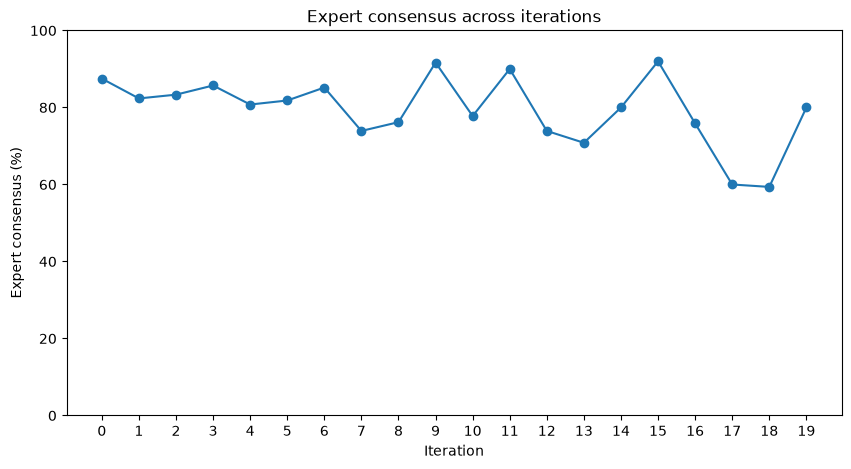

<Figure size 640x480 with 0 Axes>

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    consensus_df["iteration"],
    consensus_df["consensus_percent"],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Expert consensus (%)")
plt.title("Expert consensus across iterations")
plt.xticks(consensus_df["iteration"])
plt.ylim(0, 100)

plt.show()
plt.savefig(
    "expert_consensus_across_iterations.png",
    dpi=300,
    bbox_inches="tight"
)

In [21]:
from itertools import combinations
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

annotators = ["MODEL_PREDICTION","Pia", "Lana", "Denis"]

pairwise_results = []

# Vsak par samo enkrat
for reference, annotator in combinations(annotators, 2):

    # Uporabimo samo primere, kjer imata oba
    # jasno oznako Yes ali No
    pair = answers_with_model[
        answers_with_model[reference].isin(["Yes", "No"]) &
        answers_with_model[annotator].isin(["Yes", "No"])
    ].copy()

    # Referenčni anotator
    y_true = pair[reference].map({
        "No": 0,
        "Yes": 1
    })

    # Drugi anotator
    y_pred = pair[annotator].map({
        "No": 0,
        "Yes": 1
    })

    # Metrics
    agreement = (y_true == y_pred).mean()

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    pairwise_results.append({
        "Reference": reference,
        "Annotator": annotator,
        "N": len(pair),
        "Agreement": agreement,
        "Cohen's κ": kappa,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })


pairwise_df = pd.DataFrame(pairwise_results)

print(pairwise_df.round(3))

          Reference Annotator    N  Agreement  Cohen's κ  Precision  Recall  \
0  MODEL_PREDICTION       Pia  627      0.775      0.469      0.736   0.542   
1  MODEL_PREDICTION      Lana  658      0.845      0.653      0.794   0.746   
2  MODEL_PREDICTION     Denis  636      0.847      0.654      0.807   0.729   
3               Pia      Lana  623      0.831      0.590      0.630   0.803   
4               Pia     Denis  603      0.846      0.617      0.658   0.801   
5              Lana     Denis  632      0.915      0.803      0.892   0.840   

   F1-score  
0     0.624  
1     0.769  
2     0.766  
3     0.706  
4     0.722  
5     0.865  


In [22]:
# samo primeri kjer so vsi trije brez ??


annotators = ["MODEL_PREDICTION", "Pia", "Lana", "Denis"]

# Samo kontigi, kjer imajo vsi veljavno oznako
common_answers = answers_with_model[
    answers_with_model[annotators]
    .isin(["Yes", "No"])
    .all(axis=1)
].copy()

print("Skupno število kontigov:", len(common_answers))

from itertools import combinations
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

annotators = ["MODEL_PREDICTION","Pia", "Lana", "Denis"]

pairwise_results = []

# Vsak par samo enkrat
for reference, annotator in combinations(annotators, 2):

    # Uporabimo samo primere, kjer imata oba
    # jasno oznako Yes ali No
    pair = common_answers.copy()

    # Referenčni anotator
    y_true = pair[reference].map({
        "No": 0,
        "Yes": 1
    })

    # Drugi anotator
    y_pred = pair[annotator].map({
        "No": 0,
        "Yes": 1
    })

    # Metrics
    agreement = (y_true == y_pred).mean()

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    pairwise_results.append({
        "Reference": reference,
        "Annotator": annotator,
        "N": len(pair),
        "Agreement": agreement,
        "Cohen's κ": kappa,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })


pairwise_df = pd.DataFrame(pairwise_results)

print(pairwise_df.round(3))


Skupno število kontigov: 599
          Reference Annotator    N  Agreement  Cohen's κ  Precision  Recall  \
0  MODEL_PREDICTION       Pia  599      0.783      0.482      0.745   0.547   
1  MODEL_PREDICTION      Lana  599      0.855      0.672      0.802   0.759   
2  MODEL_PREDICTION     Denis  599      0.860      0.679      0.829   0.739   
3               Pia      Lana  599      0.838      0.605      0.635   0.819   
4               Pia     Denis  599      0.846      0.617      0.657   0.799   
5              Lana     Denis  599      0.922      0.817      0.901   0.849   

   F1-score  
0     0.631  
1     0.780  
2     0.781  
3     0.716  
4     0.721  
5     0.874  
